# 제5교시. MHA·GQA와 실제 KV 캐시


## 이번 교시의 목표

- 실제 GPT-2와 SmolLM2의 KV 캐시 shape에서 각 축과 MHA·GQA 차이를 설명합니다.
- 한 토큰 처리 전후 캐시 증가량을 계산하고 캐시 경로와 전체 재계산의 로짓을 비교합니다.
- 층당 비율·모델 전체 비율·가상 동일 조건 비율을 구분합니다.

## 이번 교시 핵심 용어

- **멀티헤드 어텐션(multi-head attention, MHA)**: 각 Query 헤드에 대응하는 Key·Value 헤드를 각각 두는 방식입니다.
- **그룹 쿼리 어텐션(grouped-query attention, GQA)**: 여러 Query 헤드가 한 그룹의 Key·Value 헤드를 공유하는 방식입니다.
- **멀티쿼리 어텐션(multi-query attention, MQA)**: 모든 Query 헤드가 하나의 Key·Value 헤드를 공유하는 방식입니다.
- **키·값 캐시(key–value cache, KV cache)**: 이미 처리한 토큰의 K·V를 보관해 다음 계산에 재사용하는 저장소입니다.
- **캐시 데이터 크기(KV payload)**: 캐시에 저장된 K·V 텐서 원소의 논리적 바이트 합이며 전체 GPU 메모리 사용량과 다릅니다.

## 실습 준비

제1교시 가상환경 커널을 선택합니다. 두 모델을 동일한 FP32(원소당 4바이트)로 읽습니다. 이전 교시와 같은 캐시라면 다운로드가 필요 없습니다. 없으면 공식 파일을 받아야 하므로 두 모델의 가중치 합계 약 817MB와 설정·토크나이저에 대한 인터넷 접근이 필요합니다. 새 패키지는 설치하지 않습니다.

아래 보조 함수는 실제 캐시의 각 층 `keys`, `values`에 대해 `원소 수 × 원소당 바이트`를 합칩니다. 캐시 구조는 확인된 Transformers 구현을 따릅니다. 환경변수로 별도 검증 캐시를 지정할 수 있지만, 일반 교육생은 설정할 필요가 없습니다.

**열기와 실행:** VS Code에서 이 `.ipynb`를 열고 오른쪽 위 커널 선택에서 제1교시에 준비한 프로젝트 가상환경의 Python을 선택합니다. 그림과 필요한 설정은 노트북에 내장되어 있으므로 별도 가이드북이나 그림 파일을 열 필요가 없습니다. 제1교시의 CUDA 지원 PyTorch와 `transformers==5.23.0` 준비가 필요합니다. 첫 다운로드에는 인터넷이 필요하며 두 모델을 차례로 관찰합니다.

**진행과 문제 확인:** 위에서부터 개념·그림·코드 설명을 확인하고 해당 코드 셀을 실행한 뒤 바로 아래 출력 설명과 대조합니다. 앞 셀의 변수와 함수를 다음 셀이 사용하므로 중간부터 실행하지 않습니다. 오류가 나면 이후 셀을 진행하지 말고 오류 전문과 마지막 성공 셀을 보존하세요. `NameError`는 앞 셀 실행 여부, `ModuleNotFoundError`는 선택한 커널과 제1교시 준비 상태, `AssertionError`는 바로 위 검사 조건과 출력값을 확인합니다. 버전이나 커널을 바꾼 뒤에는 처음부터 다시 실행하고 실행 출력이 포함된 노트북을 저장합니다. PASS는 각 셀에 적힌 검사 범위만을 뜻합니다.

같은 문장을 **실제 학습된 GPT-2와 SmolLM2-135M 전체 모델**에 각각 넣고, 모델이 보관한 K와 V 텐서를 직접 읽습니다. 제2·4교시의 고정된 가중치를 재사용합니다. 모델을 축소하거나 헤드 수를 바꾸지 않습니다. 두 모델은 차례로 불러오므로 동시에 유지할 필요가 없습니다.


## 1. 환경과 관찰 도구 준비하기

### 먼저 Q·K·V와 헤드를 떠올리기
Q는 지금 찾는 정보, K는 비교할 단서, V는 비중에 따라 전달할 정보입니다. 여러 헤드는 서로 다른 투영으로 얻은 Q·K·V를 사용합니다. 새 토큰을 처리할 때 앞 토큰의 K·V를 다시 계산하지 않도록 보관하는 것이 **KV 캐시**입니다. 과거의 Q를 이번 실습의 KV 캐시에 보관하는 것은 아닙니다.

- **MHA:** 각 Q 헤드에 대응하는 K·V 헤드가 있습니다. 실제 GPT-2는 12 Q / 12 KV입니다.
- **[GQA](https://aclanthology.org/2023.emnlp-main.298/):** 여러 Q 헤드가 한 K·V 헤드를 공유합니다. [실제 SmolLM2 설정](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json)은 9 Q / 3 KV이므로 한 KV 그룹에 Q가 3개입니다.
- **MQA:** 모든 Q 헤드가 K·V 헤드 하나를 공유하는 경우입니다. 이번에는 개념만 비교하고 MQA 모델을 실행하지 않습니다.

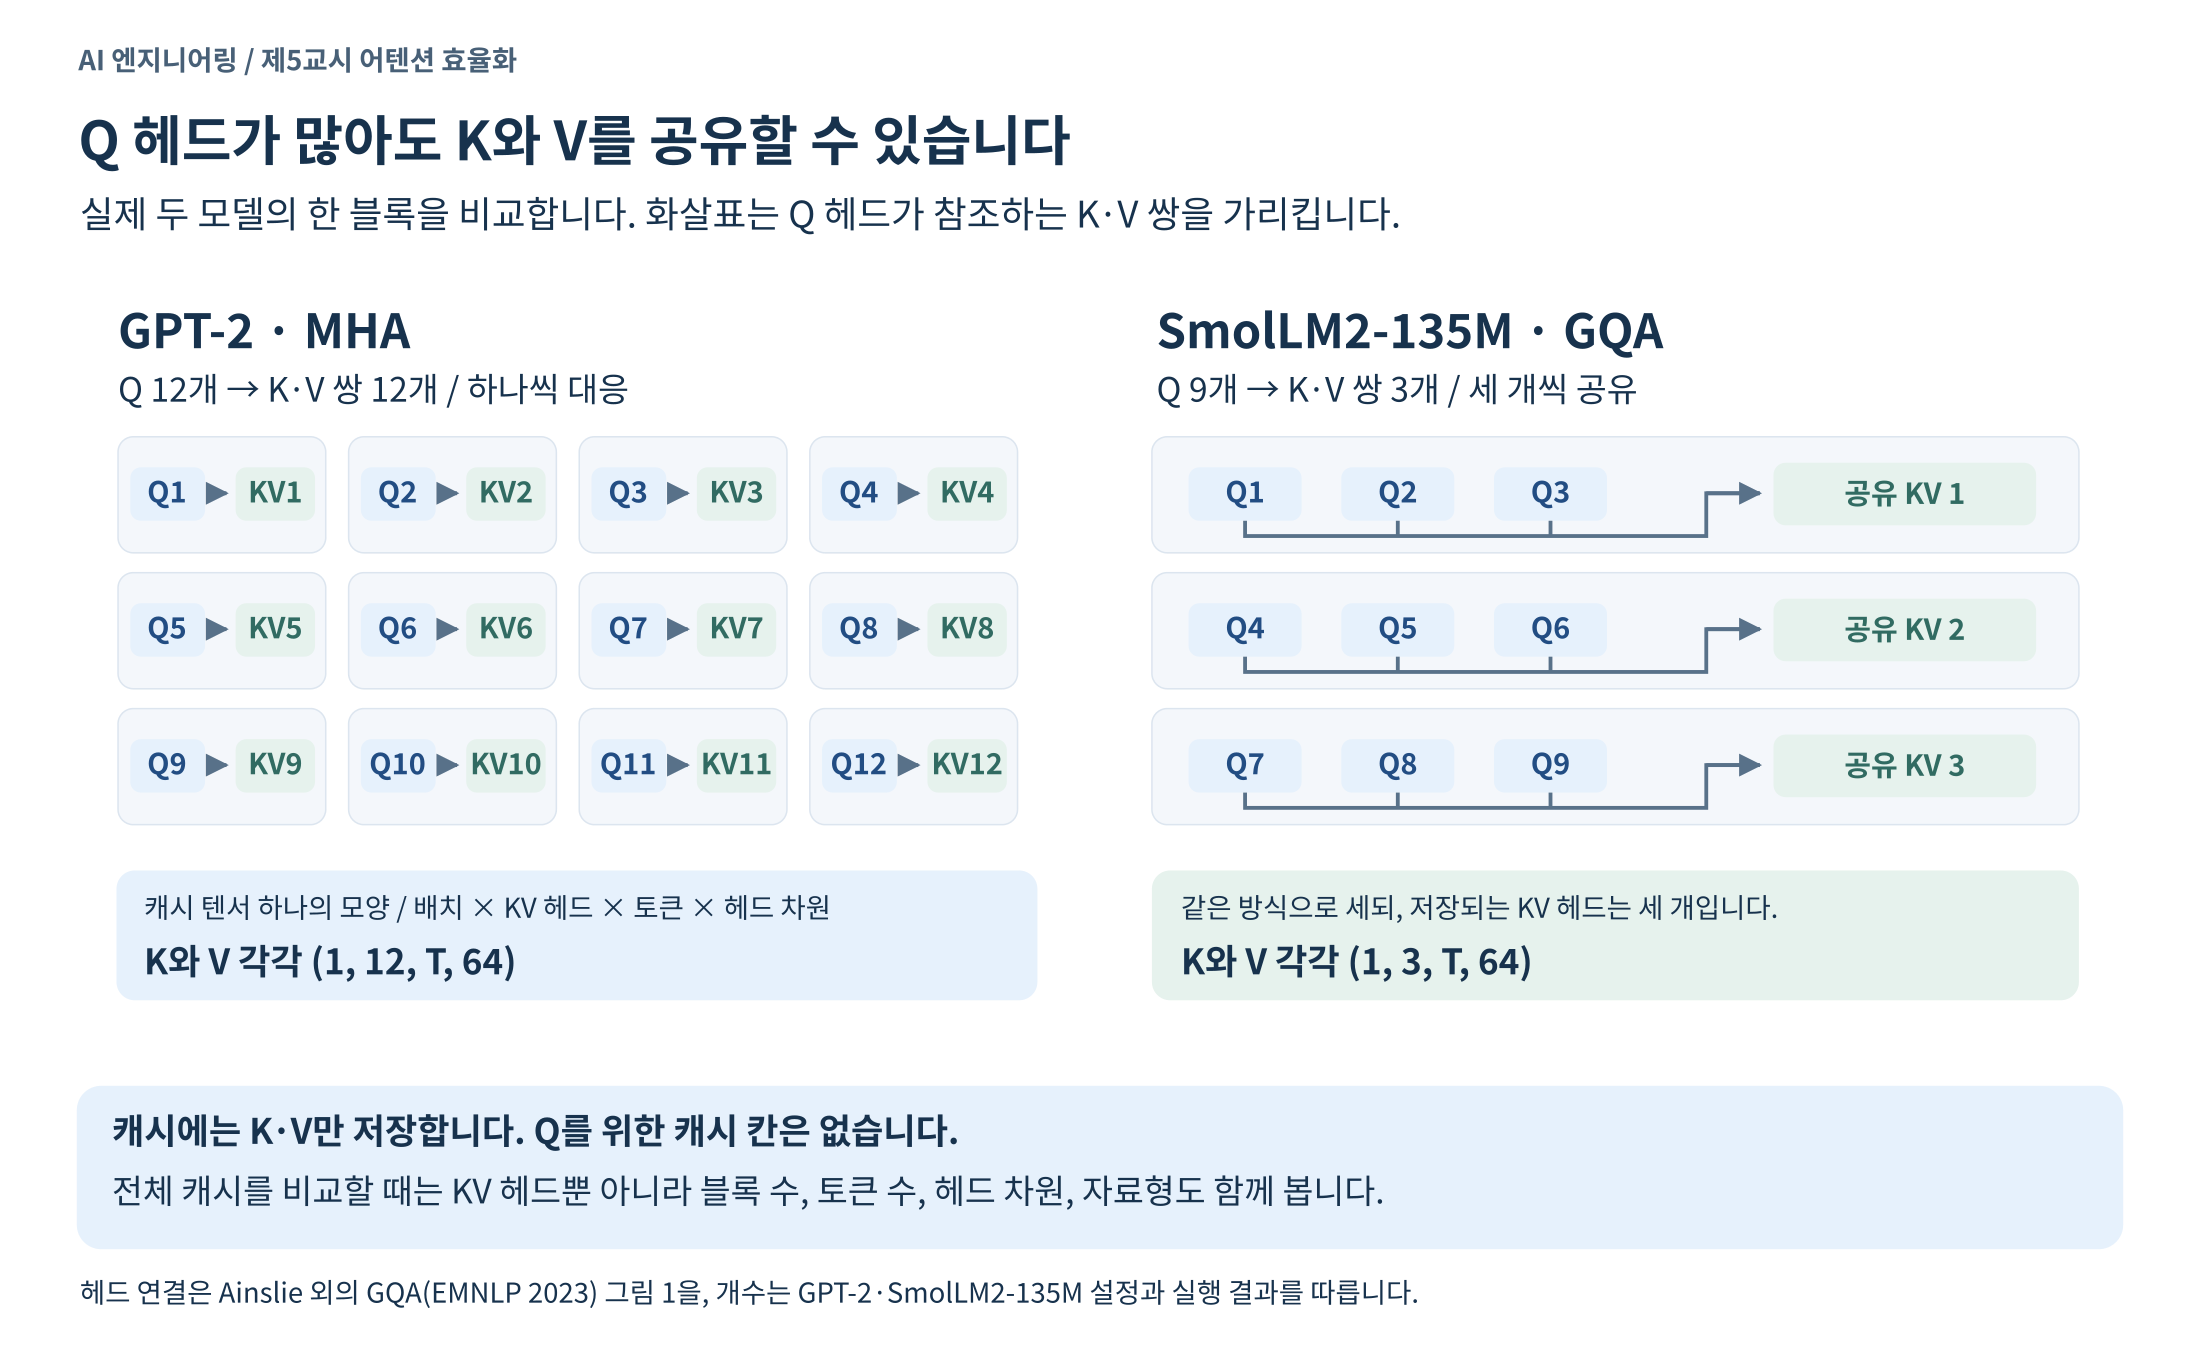

오늘 셀에서 세는 값은 **K와 V 텐서의 논리적 데이터 바이트**입니다. 모델 가중치, 활성값, 임시 계산, 메모리 할당 여유분을 포함한 GPU 전체 사용량이 아닙니다. 따라서 메모리 사용량이나 속도의 벤치마크로 읽지 않습니다.

### 개념 먼저: 이전 토큰의 K와 V는 왜 다시 계산하지 않을까요?

토큰 A, B를 이미 처리한 뒤 C를 새로 입력한다고 생각해 보세요. GPT-2에서 A는 자신만, B는 A와 자신만 참고합니다. 뒤에 C를 붙여도 A와 B는 C를 볼 수 없습니다. 그래서 같은 입력이라면 앞부분을 다시 계산해도 각 층에서 A와 B의 K(키, key)와 V(값, value)는 바뀌지 않습니다.

반면 새 토큰 C는 A, B와 자신을 모두 참고할 수 있습니다. 모델은 C의 Q(쿼리, query), K, V를 새로 계산합니다. 그런 다음 **C의 Q와 A·B·C의 K를 비교해 어텐션 가중치를 구하고, 그 가중치로 A·B·C의 V를 섞습니다.** 이때 A와 B의 K와 V는 다시 계산하지 않고 저장해 둔 값을 꺼내 씁니다. 새로 계산한 C의 K와 V도 저장해 두면, 다음 토큰을 처리할 때 다시 쓸 수 있습니다.

이렇게 각 층에서 이미 계산한 K와 V를 보관해 두는 것이 **KV 캐시(KV cache)**입니다. 모델의 학습 가중치는 바뀌지 않습니다. 캐시에 저장하는 것은 **지금 문장을 처리하면서 만든 중간값**입니다.

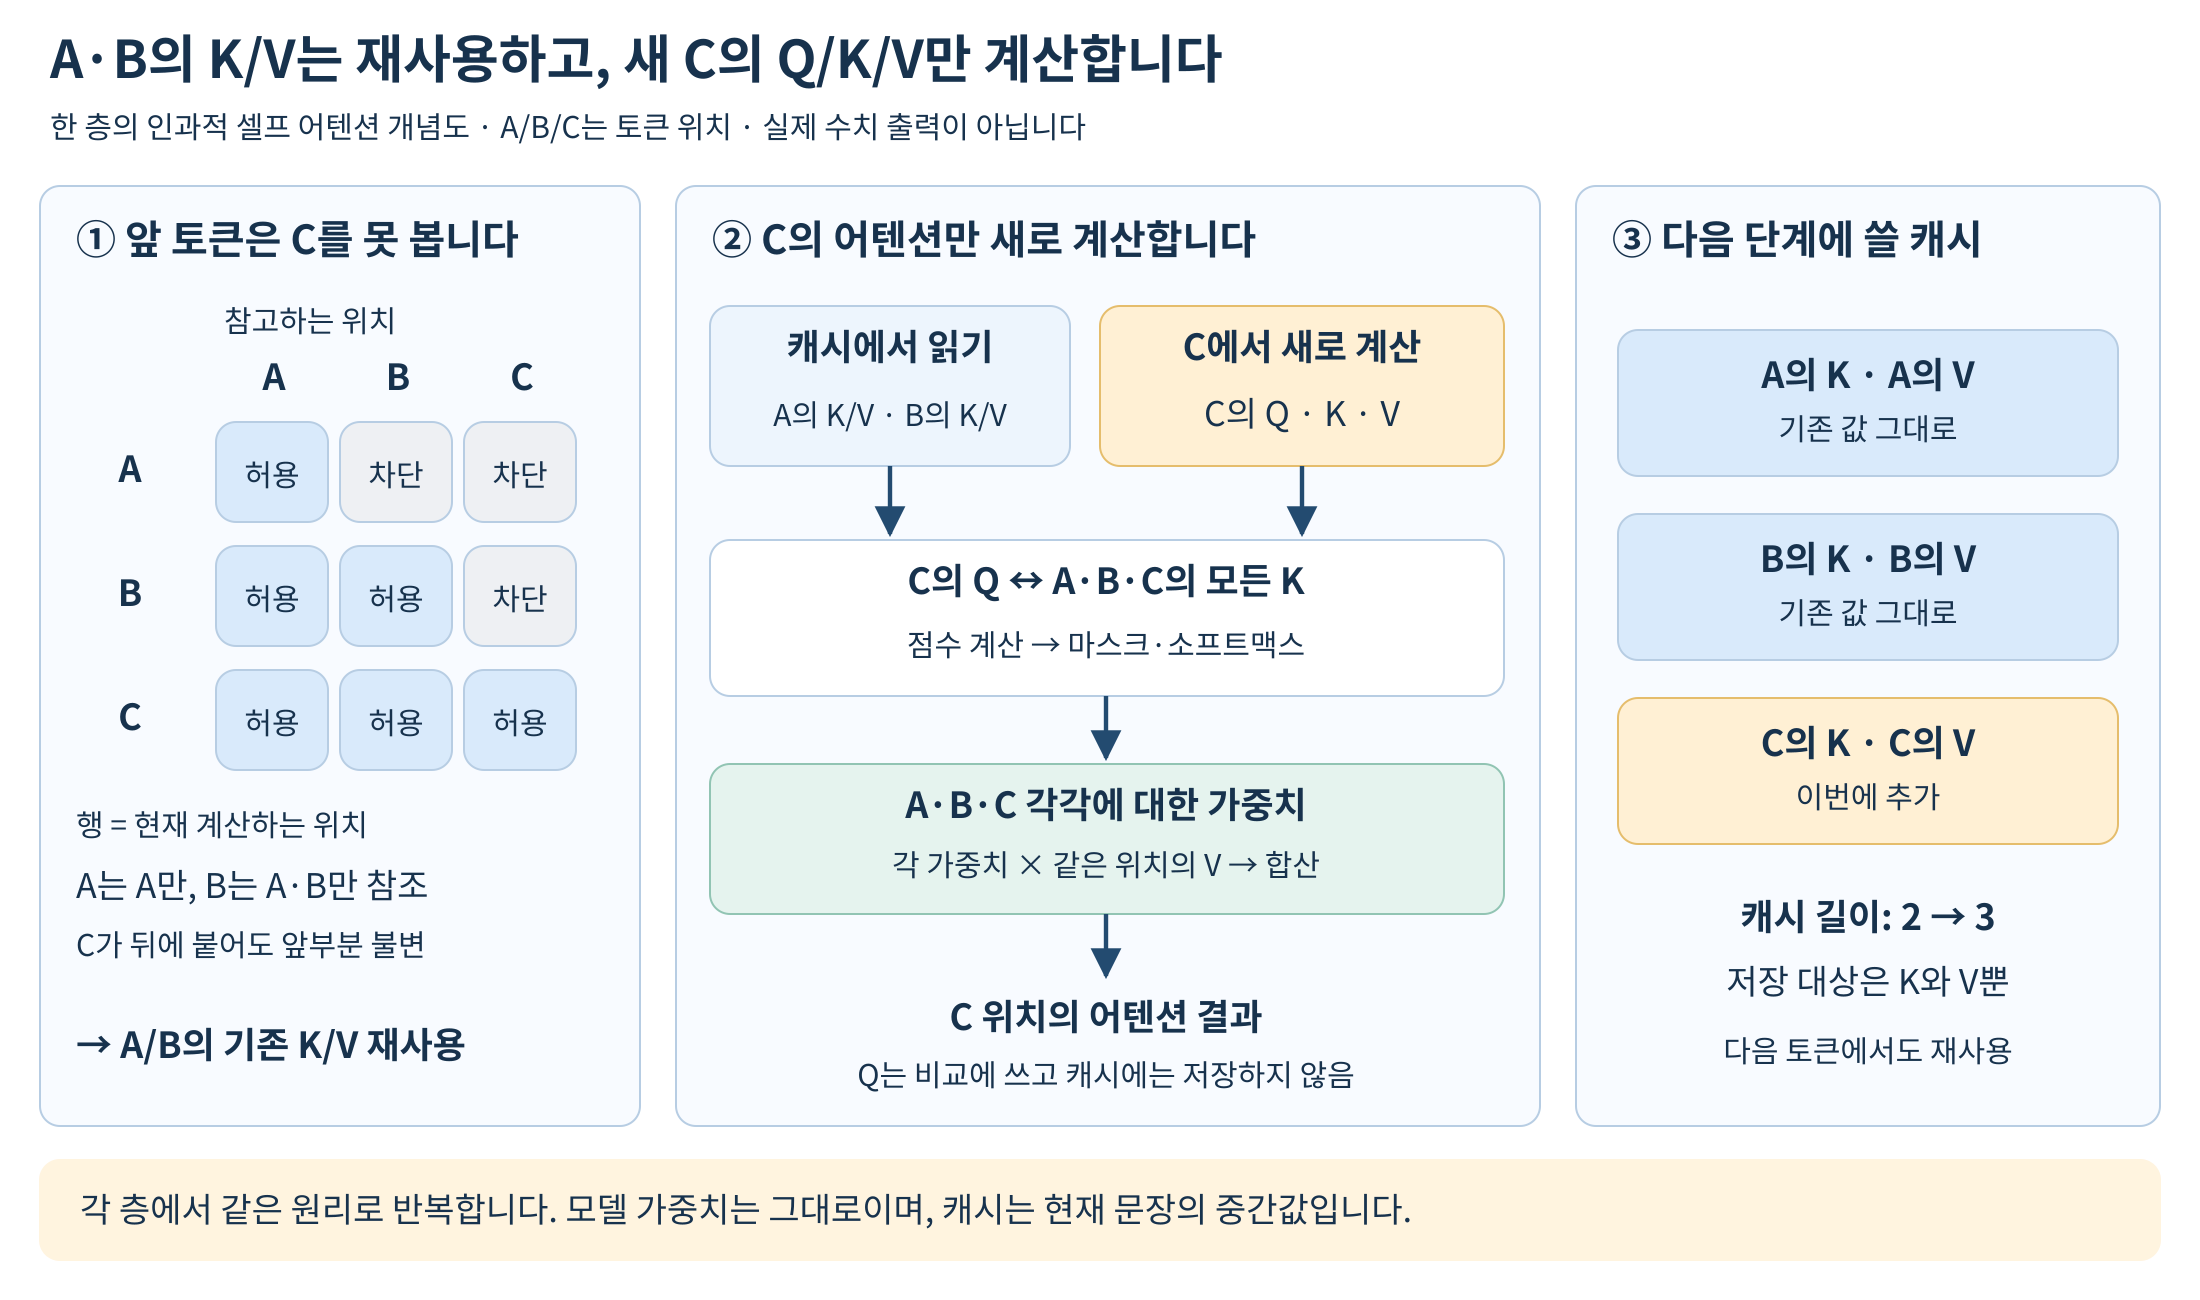

**그림 설명:** 왼쪽은 참조 가능한 위치, 가운데는 새 C의 계산, 오른쪽은 처리 후의 캐시입니다. 파란 상자는 기존 값, 주황 상자는 새로 계산한 값이며, Q는 캐시 저장 대상이 아닙니다.


### 코드 설명: 캐시를 같은 기준으로 읽는 도구 준비
**KV 캐시**는 생성 중 이미 계산한 과거 토큰의 Key와 Value를 저장해 다시 사용하는 장치입니다. 이 셀은 GPT-2와 SmolLM2를 불러오는 함수와 캐시 크기를 검사하는 함수를 정의합니다. Q 헤드 수와 KV 헤드 수를 따로 기록하므로 두 모델의 어텐션 공유 방식이 숫자로 드러납니다.

`inspect_cache`는 실제 텐서의 원소 수에 원소당 바이트 수를 곱하여 K와 V의 저장량을 합합니다. 이는 **논리적 데이터 크기**로 모델 가중치나 임시 계산 메모리까지 포함한 전체 메모리 사용량이 아닙니다. 준비 `[PASS]`만으로 캐시가 검증된 것은 아닙니다. 다음 셀에서 실제 forward가 만든 캐시를 이 함수에 넣어 확인합니다.


In [1]:
import os, sys, platform, gc
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

assert platform.system() == "Windows", "Windows 11 실습 환경을 사용하세요."
# CUDA 조건이 맞지 않으면 모델을 받기 전에 중단합니다.
assert torch.cuda.is_available(), "제1교시 CUDA와 프로젝트 커널을 확인하세요."
# 장치 지정만 준비합니다. 텐서·모델의 실제 이동은 생성 옵션 또는 to(device)가 수행합니다.
device = torch.device("cuda:0")
prompt = "The students learn AI today."
# 현재 커널이 읽은 Python 정보입니다. 설치 명령을 실행한 다른 환경과 구분합니다.
print("Python:", sys.version.split()[0], "OS:", platform.system())
print("torch:", torch.__version__, "transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))

# 모델별 Q/KV 헤드와 층 수를 따로 기록하여 같은 계산 단위로 비교합니다.
SPECS = {
    "GPT-2": dict(repo="openai-community/gpt2", revision="607a30d783dfa663caf39e06633721c8d4cfcd7e",
                  cache_env="LESSON05_GPT2_CACHE", layers=12, q_heads=12, kv_heads=12, head_dim=64),
    "SmolLM2": dict(repo="HuggingFaceTB/SmolLM2-135M", revision="93efa2f097d58c2a74874c7e644dbc9b0cee75a2",
                    cache_env="LESSON05_SMOL_CACHE", layers=30, q_heads=9, kv_heads=3, head_dim=64),
}
# 이 함수 호출 시 실제 가중치를 읽습니다. 정의만 실행한 준비 셀에서는 모델을 로드하지 않습니다.
def load_model(name):
    spec = SPECS[name]
    # 일반 실행은 기본 캐시, 강사 검증은 지정한 기존 캐시를 재사용합니다.
    kwargs = dict(revision=spec["revision"], cache_dir=os.environ.get(spec["cache_env"]) or None)
    # 모델과 같은 어휘·revision을 읽어 ID와 가중치 행의 대응을 맞춥니다.
    tokenizer = AutoTokenizer.from_pretrained(spec["repo"], **kwargs)
    # 출력 헤드까지 포함한 학습 가중치를 로드합니다. eval은 기울기 기록을 끄지는 않습니다.
    model = AutoModelForCausalLM.from_pretrained(
        spec["repo"], **kwargs, use_safetensors=True,
        # 관찰 가능한 eager 구현과 FP32 계산을 선택합니다. 모델 크기를 줄이지 않습니다.
        attn_implementation="eager", dtype=torch.float32,
    ).to(device).eval()
    # 문자열을 ID와 유효 위치 마스크의 묶음으로 만듭니다. 인과 마스크는 모델 내부에 별도로 적용됩니다.
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    if name == "GPT-2":
        # 모델별 설정 이름을 층·Q헤드·KV헤드·헤드폭의 공통 순서로 맞춥니다.
        actual = (model.config.n_layer, model.config.n_head, model.config.n_head,
                  model.config.n_embd // model.config.n_head)
    else:
        # GQA 모델은 Q와 KV 헤드 수가 다르므로 각각의 설정을 읽습니다.
        actual = (model.config.num_hidden_layers, model.config.num_attention_heads,
                  model.config.num_key_value_heads, model.config.hidden_size // model.config.num_attention_heads)
    assert actual == (spec["layers"], spec["q_heads"], spec["kv_heads"], spec["head_dim"])
    # 일부만 옮겨진 상태가 아닌지 모든 학습 파라미터의 장치를 확인합니다.
    assert all(p.device.type == "cuda" for p in model.parameters())
    return model, tokenizer, inputs

# 설정만 읽는 대신 모든 층의 실제 K/V 모양·자료형·장치와 바이트를 검사합니다.
def inspect_cache(name, cache, expected_length):
    spec = SPECS[name]
    assert len(cache.layers) == spec["layers"]
    # 이미 처리한 위치 수가 요청한 길이와 같은지 확인합니다. 선택만 한 새 ID는 포함되지 않습니다.
    assert cache.get_seq_length() == expected_length
    total = 0
    for layer in cache.layers:
        # 층별 K/V는 같은 모양이지만 다른 값을 담습니다. Q는 여기에 저장하지 않습니다.
        key, value = layer.keys, layer.values
        assert key.shape == value.shape == (1, spec["kv_heads"], expected_length, spec["head_dim"])
        assert key.dtype == value.dtype == torch.float32
        assert key.device.type == value.device.type == "cuda"
        # 실제 K/V 원소의 저장량만 합하며 모델 가중치나 메모리 관리 비용은 제외합니다.
        total += key.numel() * key.element_size() + value.numel() * value.element_size()
    first_key = cache.layers[0].keys
    # K/V 두 벌 × KV 헤드 수 × 헤드 폭 × 원소당 바이트입니다.
    per_layer_per_token = 2 * spec["kv_heads"] * spec["head_dim"] * first_key.element_size()
    # 층 수와 처리 토큰 수를 곱해 전체 논리적 데이터 크기를 계산한 뒤 실제 합계와 대조합니다.
    expected_total = spec["layers"] * expected_length * per_layer_per_token
    assert total == expected_total
    print(name, "first K/V shape:", tuple(first_key.shape), "/", tuple(cache.layers[0].values.shape))
    print("layers:", len(cache.layers), "tokens:", expected_length, "element bytes:", first_key.element_size())
    print("K+V bytes per layer per token:", per_layer_per_token)
    print("Total logical K+V payload bytes:", total)
    # 바이트 수와 길이를 이름 붙여 반환하여 다음 셀의 증가량·비율 계산에 재사용합니다.
    return dict(tokens=expected_length, total_bytes=total, per_layer_per_token=per_layer_per_token)

metrics = {}
print("[PASS] 캐시 관찰 환경·도구 준비")

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10 OS: Windows
torch: 2.9.1+cu126 transformers: 5.23.0
GPU: NVIDIA GeForce RTX 4090
[PASS] 캐시 관찰 환경·도구 준비


### 출력 설명: 실행 기록과 확인 범위

- NVIDIA GeForce RTX 4090와 패키지 버전이 출력되고 PASS에 도달했습니다. 이는 실행 환경을 확인하고 모델 로딩·캐시 검사 함수를 정의했다는 뜻입니다. 이 시점에는 함수 본문을 호출하지 않았으므로 어느 모델의 KV 캐시도 아직 측정하지 않았습니다.
- 다음 셀부터 K/V 텐서의 모양과 원소 수를 읽습니다. 여기서 비교할 수치는 모델 파일의 다운로드 캐시가 아니라 **문장 처리 중 만들어지는 어텐션 K/V 값**의 바이트 수입니다.


## 2. 실제 GPT-2: 12개 K·V 헤드 보관하기
같은 프롬프트를 넣고 `use_cache=True`로 실제 캐시를 받습니다. `(1, 12, T, 64)`의 각 축은 문장 수, **KV 헤드 수**, 처리한 토큰 수, 헤드당 차원입니다.

캐시는 어휘 점수(logits)가 아니라 K·V 벡터입니다.

**한 층·한 토큰을 저장하는 데 왜 6,144바이트가 들까요?**

첫 층에서 입력 문장 하나와 토큰 위치 하나만 골라 봅시다. `(1, 12, T, 64)`에서 문장 축과 토큰 축은 각각 한 칸만 고른 셈입니다. K(키, key)와 V(값, value)에는 각각 **헤드 12개 × 헤드당 실수 64개**가 남습니다.

1. **헤드 하나:** 실수 하나가 FP32(32비트 부동소수점)이므로 4바이트입니다. 따라서 K 헤드 하나는 `64 × 4 = 256바이트`입니다.
2. **K 전체:** K 헤드 12개를 합하면 `12 × 256 = 3,072바이트`입니다. V도 모양과 자료형이 같아서 `3,072바이트`입니다.
3. **K와 V를 모두 저장:** 두 텐서를 합하면 `3,072 + 3,072 = 6,144바이트`입니다. 즉 `2 × 12 × 64 × 4`에서 **2는 K와 V**, **12는 KV 헤드 수**, **64는 헤드당 원소 수**, **4는 원소당 바이트 수**입니다. 여기서 12는 블록 수가 아닙니다. Q(쿼리, query)는 이 캐시에 저장하지 않으므로 세지 않습니다.

이 값은 한 층·한 토큰의 K/V 데이터만 센 것입니다. 아래에서 코드가 실제 캐시 텐서를 읽어 얻은 값과 비교합니다.

### 개념 먼저: KV 캐시의 축은 무엇을 세나요?

캐시에서 문장 수·KV 헤드 수·처리한 토큰 수·헤드 차원을 각각 셉니다. 토큰을 더 처리하면 길이 축이 늘고, 헤드를 공유하면 KV 헤드 축이 작아집니다. 텐서 데이터 크기는 이 축들과 숫자 저장 형식을 함께 고려해야 합니다.

한 층의 K 텐서만 보지 말고 V도 별도로 저장된다는 점을 포함합니다. FP32의 원소 하나는 4바이트이므로 원소 개수와 저장 바이트는 같은 수가 아닙니다. 아래에서는 모든 층의 실제 배열을 세어 합산한 값과 축 크기로 계산한 값을 대조합니다. 이 합계에는 모델 가중치나 임시 작업 메모리가 들어 있지 않습니다.


### 코드 설명: GPT-2의 MHA 캐시를 실제로 열어 보기
**MHA**는 각 Query 헤드에 대응하는 Key·Value 헤드도 각각 두는 방식입니다. GPT-2는 Q와 KV 모두 12개 헤드입니다. `use_cache=True`로 입력 문장을 처리하면 출력의 `past_key_values`에 이후 생성에서 재사용할 K/V가 담깁니다. 이는 모델의 학습 가중치가 아니라 현재 입력 문장에 따라 만들어진 중간 데이터입니다.

첫 캐시의 shape `(1, 12, T, 64)`를 문장 수, KV 헤드 수, 토큰 수, 헤드 차원으로 읽으세요. FP32에서는 K와 V를 합한 층당·토큰당 데이터가 6144바이트입니다. `[PASS]`는 모든 층의 모양과 저장량을 확인했다는 뜻입니다. 문장이 길어질수록 어느 축이 늘어날지 다음 셀 실행 전에 예상해 보세요.


In [2]:
model, tokenizer, inputs = load_model("GPT-2")
# 두 번째 축은 입력 토큰 수입니다. 문자 수나 단어 수와 항상 같지는 않습니다.
T = inputs["input_ids"].shape[1]
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 입력 묶음을 이름 있는 인자로 펼칩니다. logits는 위치별 어휘 점수입니다.
    result = model(**inputs, use_cache=True)
# 입력 문장의 forward가 만든 K/V를 다음 한 토큰 계산에 재사용합니다.
cache = result.past_key_values
print("GPT-2 input IDs:", inputs["input_ids"][0].tolist())
metrics["GPT-2"] = inspect_cache("GPT-2", cache, T)
assert metrics["GPT-2"]["per_layer_per_token"] == 6144
print("[PASS] 실제 GPT-2 MHA 캐시")

W1117 21:53:30.799000 32420 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 4/148 [00:00<00:03, 38.20it/s]

Loading weights:   5%|▌         | 8/148 [00:00<00:04, 32.23it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 600.63it/s]

GPT-2 input IDs: [464, 2444, 2193, 9552, 1909, 13]
GPT-2 first K/V shape: (1, 12, 6, 64) / (1, 12, 6, 64)
layers: 12 tokens: 6 element bytes: 4
K+V bytes per layer per token: 6144
Total logical K+V payload bytes: 442368
[PASS] 실제 GPT-2 MHA 캐시


### 출력 설명: 실행 기록과 확인 범위

- K와 V 각각의 `(1, 12, 6, 64)`는 문장 1개, KV 헤드 12개, 처리한 토큰 6개, 헤드당 성분 64개입니다. 두 텐서는 같은 모양이지만 내용과 역할은 다릅니다.
- `element bytes`가 4이므로 FP32 원소 하나가 4바이트입니다. 한 층·한 토큰의 K+V 저장량 6,144바이트는 **K/V 두 벌 × 12헤드 × 64성분 × 4바이트**입니다. 여기에 6토큰과 12층을 곱한 442,368바이트가 전체 논리적 payload입니다.
- PASS는 모든 층의 모양·자료형·CUDA 배치와 실제 원소 수로 센 합이 이 계산과 같았음을 확인합니다. 첫 층만 표시했지만 전체 층을 검사했습니다. 모델 가중치·임시 연산 공간·메모리 관리 비용은 제외하므로 GPU 총사용량으로 읽지 않습니다.


## 3. GPT-2에 한 토큰을 더 처리시키기
프롬프트 마지막 위치에서 선택한 다음 토큰 하나를 실제 입력으로 넣습니다. 캐시에는 ‘선택만 한 토큰’이 아니라 **모델이 처리한 토큰**의 K·V가 추가됩니다. 전체 12층에서 한 토큰분이 늘어납니다.

전체 입력을 캐시 없이 다시 계산한 마지막 점수와도 대조합니다. 계산 경로에 따른 작은 부동소수점 차이는 허용하지만 같은 모델·같은 입력이어야 합니다. 이 단계에서는 시간을 비교하지 않습니다.

### 개념 먼저: 토큰 선택과 토큰 처리는 다른 순간입니다

앞의 예에서 **A·B를 이미 모델에 넣어 처리했다**고 생각해 보세요. 이때 캐시에는 A와 B의 K·V가 들어 있어 길이가 2입니다. 모델이 이미 내놓은 점수 중 **마지막인 B 위치의 점수(로짓, logits)**로 이제 B 뒤에 올 토큰을 고를 수 있습니다.

1. **C를 선택합니다.** 이 실습에서는 B 위치의 점수에서 가장 높은 값을 찾아 그 토큰의 ID를 `next_id`에 담습니다. 그 ID를 글자로 바꿔 화면에 보여 줄 수도 있습니다. 하지만 여기까지는 점수에서 ID를 골랐을 뿐, C를 모델에 넣지 않았습니다. **C의 K·V는 아직 없고 캐시 길이도 2 그대로**입니다.
2. **선택한 C를 처리합니다.** 모델에 C의 ID 하나와 A·B의 KV 캐시를 함께 넣습니다. 모델은 A·B의 K·V를 다시 계산하지 않고 C의 K·V를 새로 만들어 붙입니다. **이때 캐시 길이가 2에서 3으로 늘어납니다.** 화면에 C를 표시해서 늘어난 것이 아니라, 모델이 C를 실제로 계산했기 때문에 늘어난 것입니다. 이번 실행에서 나온 C 위치의 점수는 C 뒤에 올 토큰의 후보 점수입니다. 이 점수가 나왔다고 해서 그다음 토큰까지 이미 고른 것은 아닙니다.

이어지는 실습에서는 같은 토큰 ID를 사용해 **캐시로 새 토큰 하나만 처리한 경우**와 **앞 토큰부터 전부 다시 처리한 경우**의 마지막 위치 점수를 비교합니다. 캐시의 길이가 한 칸 늘었는지와, 두 점수가 허용 오차 안에서 같은지는 서로 다른 확인입니다.


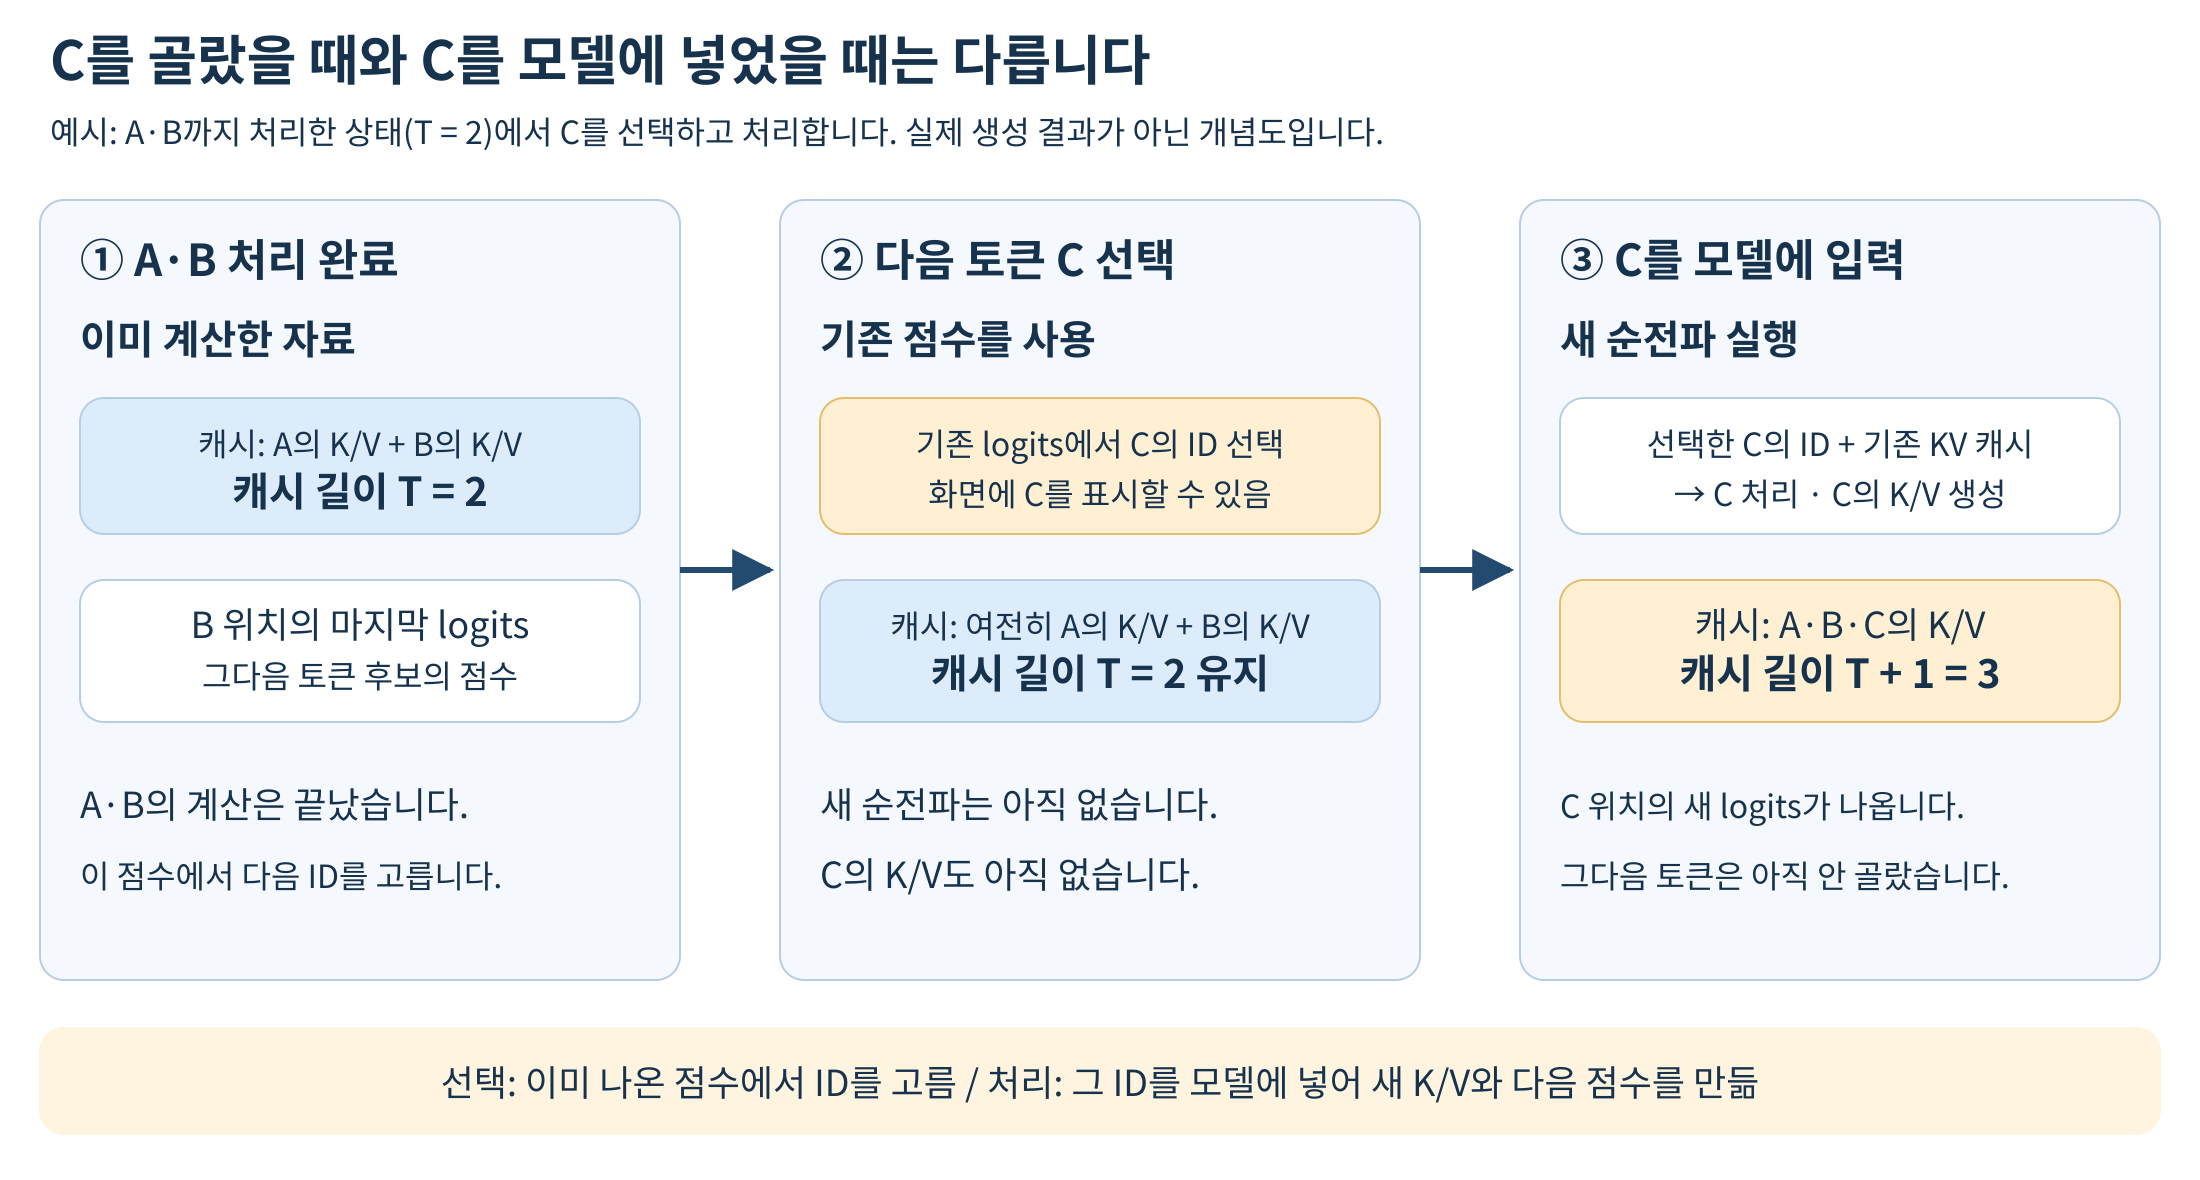

**그림 설명:** C를 선택·표시할 때는 이전 점수를 사용하므로 캐시는 그대로입니다. 선택한 C를 모델에 입력하여 처리한 뒤에만 C의 K/V가 추가됩니다. 이때 나온 새 점수에서 그다음 토큰을 고르는 일은 아직 남아 있습니다.


### 코드 설명: 캐시 재사용이 점수를 바꾸지 않는지 확인
다음 토큰 하나를 선택한 뒤 두 경로를 비교합니다. 첫 경로는 새 토큰만 모델에 보내되 과거 K/V 캐시를 함께 전달합니다. 둘째 경로는 원문과 새 토큰 전체를 캐시 없이 재계산합니다. `attention_mask`는 새 토큰 하나만이 아니라 캐시에 포함된 과거 위치까지 나타내야 하므로 전체 길이로 만듭니다.

비교 대상은 동일한 최종 입력 위치의 어휘 점수입니다. 아래의 점수 비교를 통과하고 캐시 길이가 T+1, 데이터 증가량이 `12 × 6144`바이트이면 성공입니다. 이는 이 입력에서 재사용 결과의 일치를 검증한 것이며 속도를 측정한 것은 아닙니다. 비교가 끝나면 모델 참조를 해제하여 다음 모델과 불필요하게 메모리를 함께 차지하지 않게 합니다.

**이 실험에서 허용하는 차이.** 계산 순서가 다르면 같은 FP32 계산에서도 끝자리가 조금 달라질 수 있습니다. 그래서 GPT-2와 SmolLM2 모두 절대 허용 오차 `atol=1e-4`(0.0001), 상대 허용 오차 `rtol=1e-4`(0.01%)로 비교합니다. 후보 하나의 캐시 사용 점수를 `a`, 전체 재계산 점수(기준값)를 `b`라 하면, **`|a − b| ≤ 0.0001 + 0.0001 × |b|`** 일 때 그 점수가 통과합니다. 예를 들어 기준 점수가 0이면 0.0001까지, 2이면 0.0003까지 허용됩니다. 이 숫자는 실측 점수가 아니라 계산 예입니다. 마지막 위치의 모든 후보 점수가 각자의 기준을 만족해야 `allclose`가 통과합니다.


In [3]:
# 마지막 위치에서 ID 하나를 고르고 keepdim으로 (1,1) 입력 모양을 유지합니다.
next_id = result.logits[:, -1].argmax(dim=-1, keepdim=True)
# 비교용 전체 입력은 원문에 이번에 고른 토큰 하나를 붙인 것입니다.
full_ids = torch.cat([inputs["input_ids"], next_id], dim=1)
# 새 토큰만 입력해도 마스크는 캐시 속 과거 토큰을 포함한 전체 길이에 맞춥니다.
full_mask = torch.ones_like(full_ids)
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 과거 캐시와 새 ID만 처리합니다. 마스크는 과거+새 위치 전체 길이입니다.
    continued = model(input_ids=next_id, attention_mask=full_mask,
                      past_key_values=cache, use_cache=True)
    # 같은 문장 전체를 캐시 없이 다시 계산하여 마지막 위치 점수를 대조합니다.
    recomputed = model(input_ids=full_ids, attention_mask=full_mask, use_cache=False)
# 각 경로의 마지막 위치를 맞춘 뒤 모든 어휘에서 최대 절대 차이를 요약합니다.
gpt_delta = (continued.logits[:, -1] - recomputed.logits[:, -1]).abs().max().item()
# 전체 재계산의 후보별 점수 b를 기준으로 |차이| ≤ 0.0001 + 0.0001 × |b|인지 검사합니다.
# atol=0.0001(절대), rtol=0.0001(상대): 기준 점수가 2이면 허용 차이는 0.0003입니다.
assert torch.allclose(continued.logits[:, -1], recomputed.logits[:, -1], atol=1e-4, rtol=1e-4)
after = inspect_cache("GPT-2", continued.past_key_values, T + 1)
# 이번 토큰 처리 후 총량에서 이전 총량을 빼 모든 층의 한 토큰 추가량을 얻습니다.
increase = after["total_bytes"] - metrics["GPT-2"]["total_bytes"]
assert increase == 12 * 6144
print("Processed extra ID:", next_id.item(), "payload increase:", increase)
print("Cached vs full recompute logits max difference:", gpt_delta)
# 최초 여섯 토큰의 총량은 보존하고 증가량과 점수 차이만 추가합니다.
metrics["GPT-2"].update(increase=increase, logits_delta=gpt_delta)
# 2개 모델을 동시에 GPU에 유지하지 않도록 참조를 해제합니다.
del model, tokenizer, inputs, result, cache, continued, recomputed, next_id, full_ids, full_mask
# 참조가 해제된 Python 객체를 정리합니다. 런타임 연결을 끊는 명령은 아닙니다.
gc.collect()
torch.cuda.empty_cache()
print("[PASS] GPT-2 캐시 1토큰 증가·동일 입력 점수 대조")

GPT-2 first K/V shape: (1, 12, 7, 64) / (1, 12, 7, 64)
layers: 12 tokens: 7 element bytes: 4
K+V bytes per layer per token: 6144
Total logical K+V payload bytes: 516096
Processed extra ID: 1119 payload increase: 73728
Cached vs full recompute logits max difference: 9.1552734375e-05
[PASS] GPT-2 캐시 1토큰 증가·동일 입력 점수 대조


### 출력 설명: 실행 기록과 확인 범위

- 새 ID 1119를 모델에 **처리한 뒤** 캐시의 토큰 축만 6에서 7로 늘었습니다. ID를 고르는 것만으로 늘어난 것이 아닙니다. 헤드 수 12와 헤드당 폭 64는 그대로입니다.
- 전체 저장량은 516,096바이트로, 이전보다 73,728바이트 늘었습니다. 이는 새 토큰 하나에 필요한 6,144바이트가 12개 층에 추가된 양입니다. 입력 전체를 다시 계산하는 방식과 달리 기존 여섯 위치의 K/V를 재사용합니다.
- 두 경로의 마지막 위치 점수 중 최대 절대 차이는 약 0.0000916입니다. 모든 후보의 최대 차이 자체가 0.0001보다 작으므로 상대 허용분을 더하기 전에도 한도 이내입니다. PASS는 점수 비교와 캐시 증가량 검사를 통과했다는 뜻이며, 시간·VRAM 감소를 측정한 것은 아닙니다.


## 4. 실제 SmolLM2: Q 9개가 K·V 3개를 공유하기
SmolLM2는 Q 헤드가 9개지만 캐시에 보관하는 K·V 헤드는 3개입니다. Q 수와 같은 9개로 늘려 저장하지 않습니다. 어텐션 계산 도중의 표현과 보관된 캐시는 구분해야 합니다.

실제 텐서로 확인합니다. 헤드당 64차원·FP32이므로 한 층·한 토큰은 `2 × 3 × 64 × 4 = 1,536바이트`입니다. GPT-2와 토크나이저가 다르므로 같은 문장이어도 ID는 다릅니다.

### 개념 먼저: Query는 여럿이어도 KV는 공유할 수 있습니다

GQA는 여러 Query 헤드가 하나의 KV 그룹을 함께 참고하는 방식입니다. 모든 Q 헤드를 없애거나 같은 헤드로 만드는 것이 아니라 K/V 보관을 공유합니다. 저장량을 줄이는 선택이지만 이 실습만으로 품질이나 실제 속도 차이까지 입증하지 않습니다.

SmolLM2의 Q 헤드는 9개지만 KV는 3그룹입니다. 세 Q가 같은 K/V를 참고하더라도 각 Q가 만드는 비교 점수와 가중합은 서로 달라질 수 있습니다. 공유는 모든 헤드의 결과를 같게 만드는 장치가 아닙니다. 아래에서는 확장된 Q 수가 아니라 실제 저장된 KV 축이 3인지 확인합니다.

**왜 Q는 유지하면서 K/V를 공유할까요?** 여러 Q 헤드는 서로 다른 관점에서 정보를 찾는 질의를 유지합니다. 같은 그룹의 Q들이 K/V를 함께 써도 Q 값은 서로 다르므로 어텐션 가중치와 결과도 달라질 수 있습니다. 반면 이전 토큰에서 반복해서 읽을 K/V의 저장량은 줄일 수 있습니다. 줄이는 것은 질의의 개수가 아니라 저장되는 키·값 묶음의 개수입니다.

이번 SmolLM2는 Q 9개, K 헤드 3개, V 헤드 3개입니다. 그림의 각 행은 저장된 KV 헤드이고 각 칸은 한 토큰의 64개 성분입니다. K와 V를 따로 그렸으므로 두 배열을 모두 세어야 합니다. 행 번호는 이해를 위한 1부터의 표기이며 코드 인덱스는 0부터 시작합니다. 아래에서 실제 캐시 `(1, 3, 6, 64)`를 확인한 뒤, 한 층·한 토큰 1,536바이트와 30층 전체 276,480바이트가 맞는지 검사합니다.

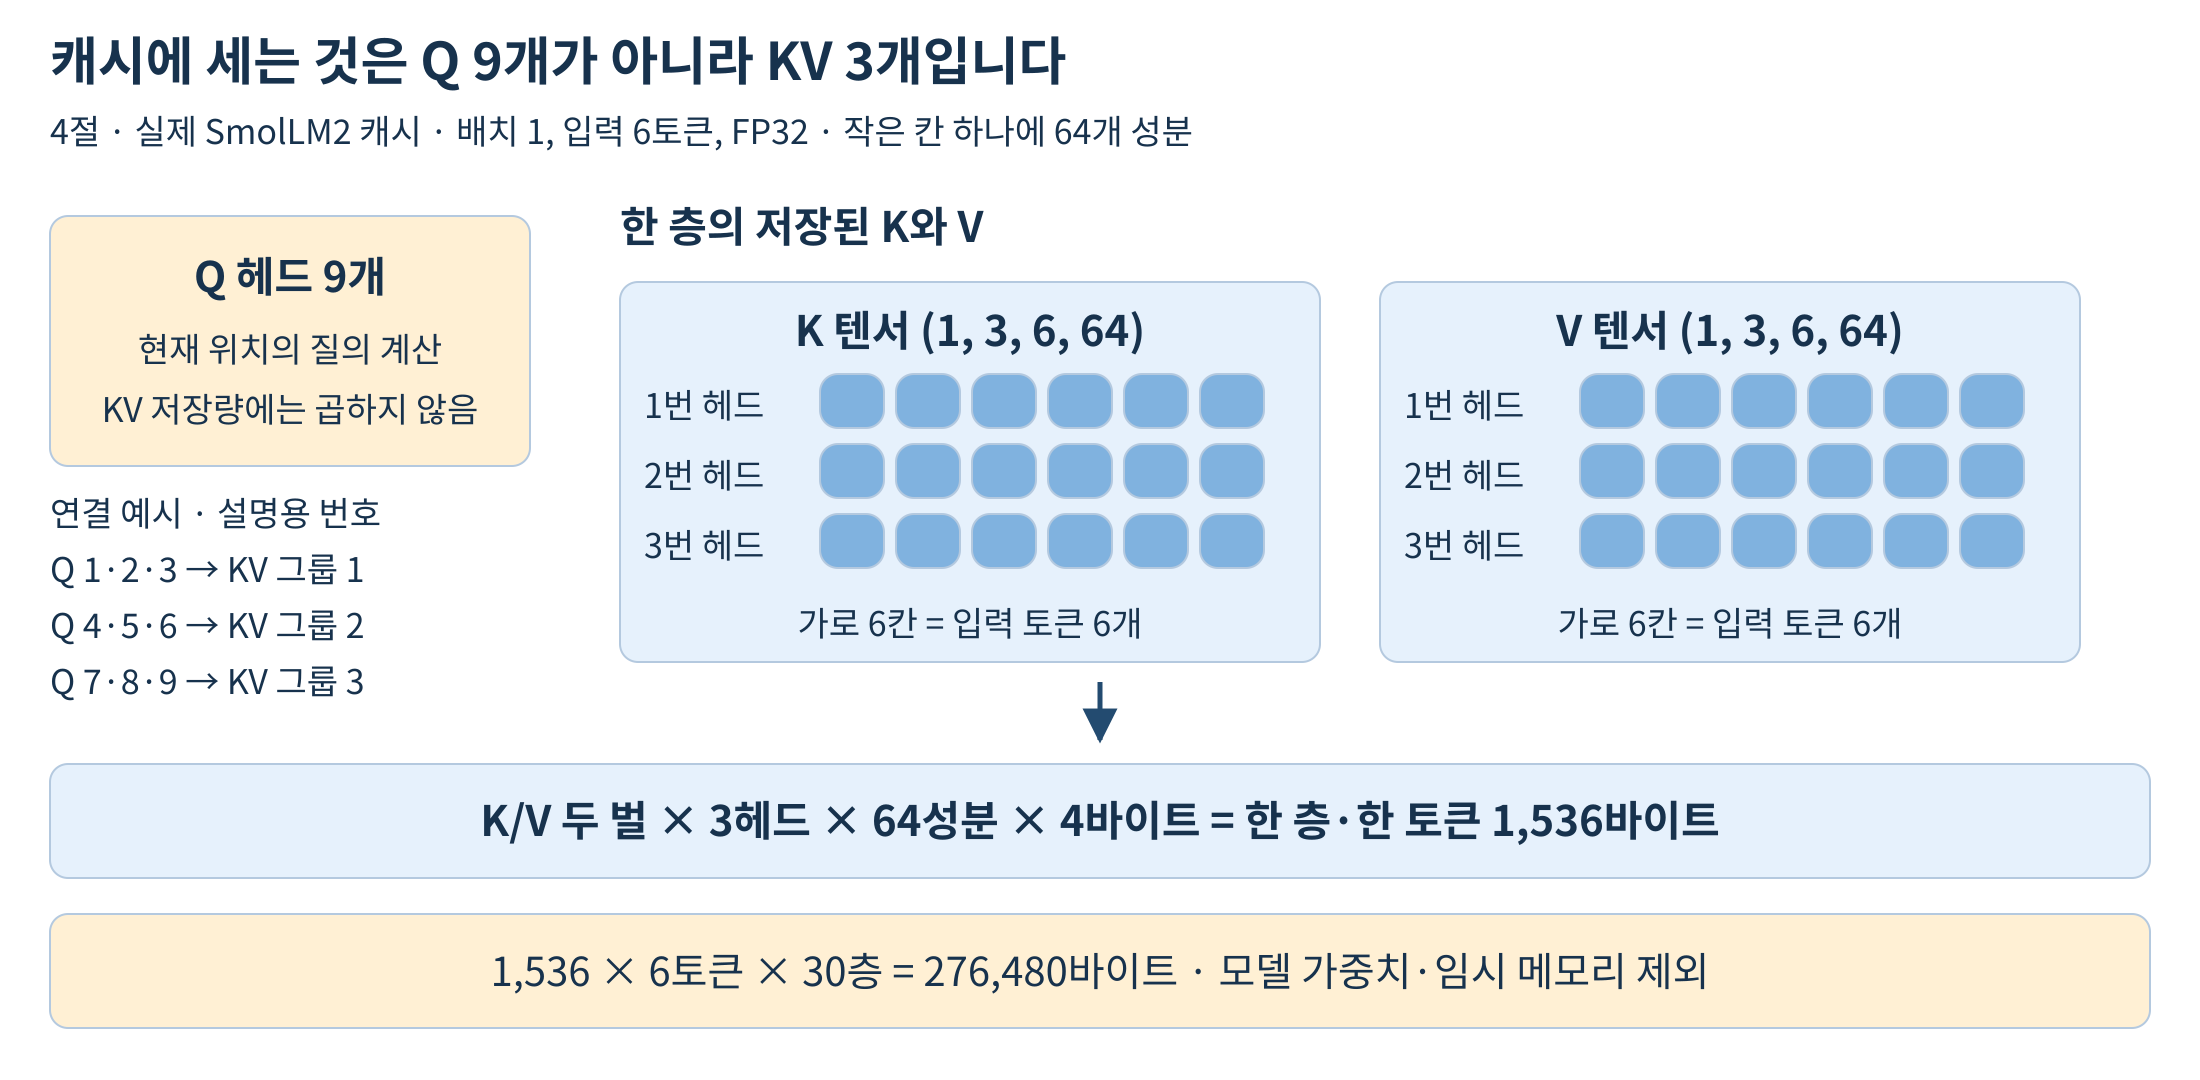

**그림 설명:** 기존의 Q/KV 연결 그림과 달리, 여기서는 **실제로 보관한 배열의 축과 바이트 수**를 셉니다. Q 헤드 9를 캐시 크기 계산에 넣지 않는 이유를 확인하세요.


### 코드 설명: SmolLM2의 GQA에서 공유되는 것
**GQA**는 여러 Query 헤드가 한 그룹의 Key·Value 헤드를 공유하는 방식입니다. 이 모델은 Q 헤드 9개와 KV 헤드 3개를 사용하므로 Query 세 개가 하나의 KV 그룹에 대응합니다. Query의 수를 모두 줄이는 방식과 다르며, 캐시에 저장되는 것은 반복 확장된 9개가 아니라 실제 KV 헤드 3개입니다.

캐시 shape `(1, 3, T, 64)`와 층당·토큰당 1536바이트를 확인하세요. 공유를 통해 KV 저장량을 줄이는 설계 의도를 볼 수 있습니다. 다만 GPT-2와는 층 수도, 가중치도, 토크나이저도 다르므로 모델 전체 메모리나 답변 품질을 이 숫자만으로 비교하지 않습니다. 마지막 셀에서 조건이 다른 비교를 분리해 해석합니다.


In [4]:
model, tokenizer, inputs = load_model("SmolLM2")
# 두 번째 축은 입력 토큰 수입니다. 문자 수나 단어 수와 항상 같지는 않습니다.
T = inputs["input_ids"].shape[1]
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 입력 묶음을 이름 있는 인자로 펼칩니다. logits는 위치별 어휘 점수입니다.
    result = model(**inputs, use_cache=True)
# 현재 문장을 처리해 만든 K/V를 꺼냅니다. 학습 가중치나 다운로드 폴더가 아닙니다.
cache = result.past_key_values
print("SmolLM2 input IDs:", inputs["input_ids"][0].tolist())
print("Q / KV heads:", model.config.num_attention_heads, model.config.num_key_value_heads)
# Query 헤드 수가 아니라 실제 저장된 KV 헤드 수로 캐시 크기를 계산합니다.
metrics["SmolLM2"] = inspect_cache("SmolLM2", cache, T)
assert metrics["SmolLM2"]["per_layer_per_token"] == 1536
print("[PASS] 실제 SmolLM2 GQA 캐시")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  53%|█████▎    | 145/272 [00:00<00:00, 1428.21it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1462.00it/s]

SmolLM2 input IDs: [504, 1058, 835, 5646, 1834, 30]
Q / KV heads: 9 3
SmolLM2 first K/V shape: (1, 3, 6, 64) / (1, 3, 6, 64)
layers: 30 tokens: 6 element bytes: 4
K+V bytes per layer per token: 1536
Total logical K+V payload bytes: 276480
[PASS] 실제 SmolLM2 GQA 캐시


### 출력 설명: 실행 기록과 확인 범위

- Q는 9헤드지만 캐시의 K/V 모양은 각각 `(1, 3, 6, 64)`입니다. 캐시에는 Q를 저장하지 않으며 KV 헤드가 3개이므로 이 축의 크기를 9로 계산하지 않습니다.
- FP32에서 한 층·한 토큰의 저장량은 **K/V 두 벌 × 3헤드 × 64성분 × 4바이트 = 1,536바이트**입니다. 6토큰·30층 전체는 276,480바이트입니다. GPT-2보다 층은 많지만 이 입력의 K/V payload는 작았습니다.
- PASS는 실제 모든 층의 텐서 모양·자료형·장치와 합계를 검사한 결과입니다. 두 모델이 같은 문장을 여섯 토큰으로 나누었더라도 ID가 다른 것은 각자 다른 어휘 표를 사용하기 때문입니다.


## 5. SmolLM2도 한 토큰을 더 처리하기
같은 절차를 SmolLM2에도 적용합니다. 전체 층이 30개이므로 캐시 증가량 계산에는 30을 곱해야 합니다. 두 모델에서 선택된 토큰 문자열이 같을 필요는 없습니다. 서로 다른 모델의 점수를 직접 대조하지 않고 **각 모델 내부에서** 캐시 사용·미사용 계산을 비교합니다.

### 개념 먼저: 다른 모델에서도 같은 비교 절차를 유지하기

SmolLM2에서도 새 토큰을 처리한 캐시 경로와 전체 재계산 경로를 비교합니다. 같은 모델의 동일 입력 두 경로를 비교해야 캐시 재사용 효과를 분리할 수 있습니다. GPT-2와 SmolLM2의 logits 값 자체를 서로 대조하는 실험은 아닙니다.

두 모델은 어휘표와 가중치가 다르므로 같은 원문에서도 토큰 ID와 다음 후보가 다를 수 있습니다. 각각의 모델 안에서 동일한 ID 시퀀스를 두 방법으로 처리해야 재사용에 따른 차이만 살펴볼 수 있습니다. 아래에서는 현재 모델의 새 ID와 기존 캐시를 사용하고, 그 모델의 전체 재계산 결과와 비교합니다.

**GQA의 공유 구조는 다음 토큰에서도 유지될까요?** 새 토큰을 처리하면 각 층의 KV 헤드 세 개에 새 위치의 K·V가 한 쌍씩 추가됩니다. Q 헤드가 아홉 개라고 새 K/V 쌍을 아홉 벌 저장하지 않습니다. 따라서 캐시 모양은 `(1, 3, 6, 64)`에서 `(1, 3, 7, 64)`로 바뀌며, 헤드 축은 3 그대로이고 토큰 축만 늘어납니다.

이번 저장 결과에서 선택된 SmolLM2 ID는 198입니다. 한 경로에는 그 ID 하나와 이전 여섯 위치의 캐시를 주고, 다른 경로에는 같은 일곱 ID 전체를 줍니다. 두 경로의 출력 위치 수는 각각 1과 7이지만 마지막 위치는 동일한 토큰을 가리킵니다. 그 위치의 어휘 점수 49,152개를 비교해야 합니다. 이는 GPT-2와 SmolLM2의 점수를 비교하는 실험이 아닙니다.

아래에서는 **공유된 캐시의 증가량**과 **계산을 재사용한 결과의 근사 일치**를 따로 확인합니다. 증가량 46,080바이트는 `30층 × 1,536바이트`이고, 점수 비교는 이어지는 코드 설명의 절대·상대 허용오차를 사용합니다. 저장량 확인과 점수 일치는 속도 측정을 대신하지 않습니다.

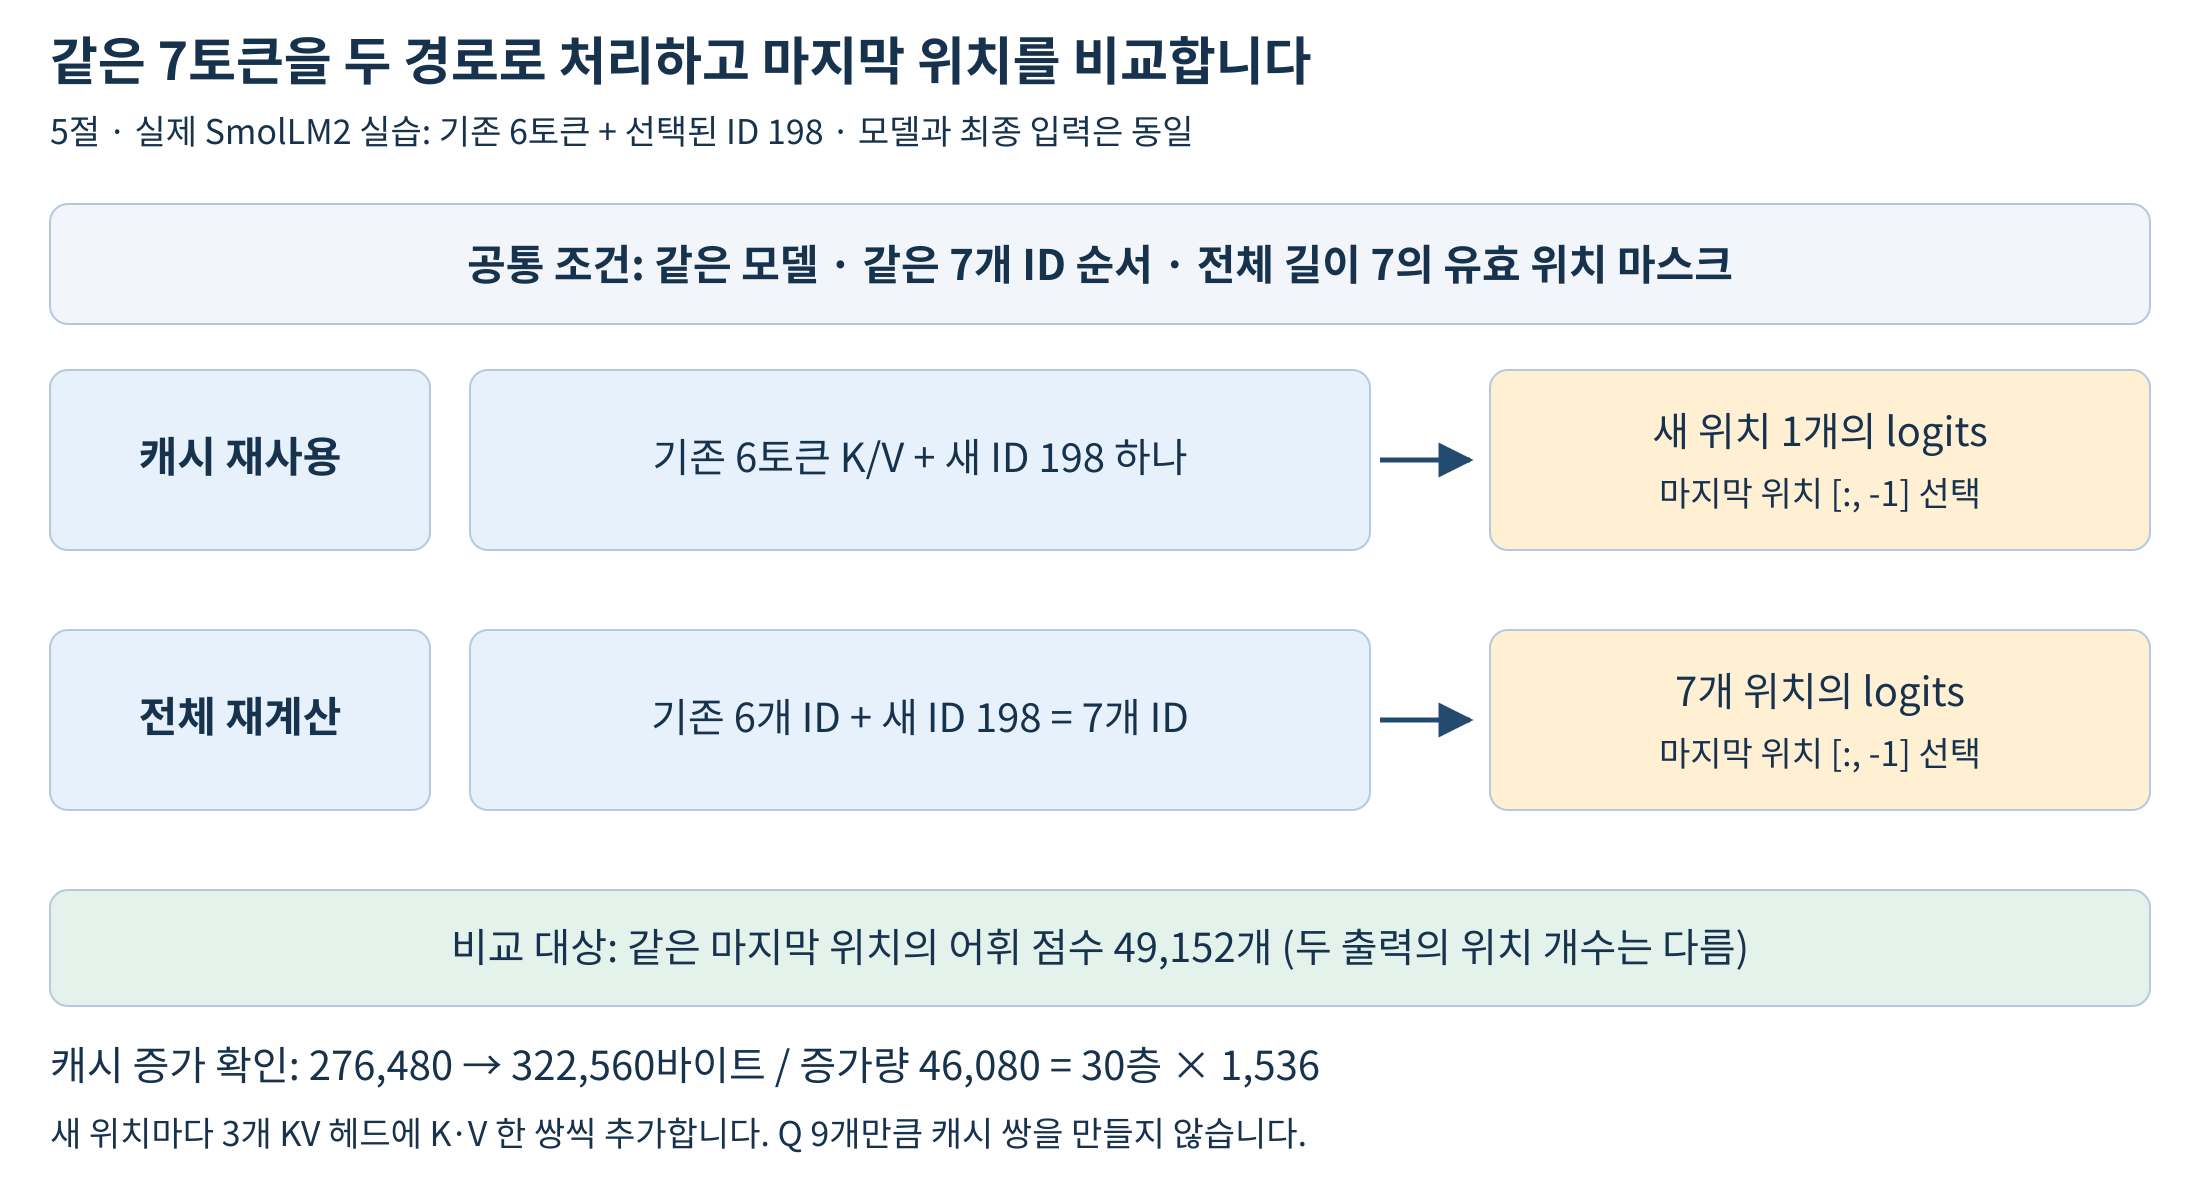

**그림 설명:** 앞의 선택·처리 그림은 **언제 캐시가 늘어나는지**를 다뤘습니다. 이 그림은 **GQA 캐시를 재사용해도 같은 최종 입력의 점수가 유지되는지 검사하는 방법**을 보여 줍니다.


### 코드 설명: GQA 캐시도 같은 방식으로 검증
GPT-2에서 했던 대조 실험을 SmolLM2에서도 반복합니다. 새 토큰 하나와 기존 캐시로 이어서 계산한 마지막 logits가, 확장 문장 전체를 다시 계산한 logits와 같은지 확인합니다. 이처럼 비교 절차를 맞추어야 캐시 구조가 달라도 재사용의 의미를 일관되게 설명할 수 있습니다.

성공 기준은 캐시 길이가 한 토큰 늘고 총 데이터 증가량이 `30 × 1536`바이트이며 전체 재계산을 기준으로 모든 후보 점수가 `atol=1e-4`, `rtol=1e-4` 판정을 통과하는 것입니다. GPT-2와 같은 `0.0001 + 0.0001 × |기준 점수|` 한도를 적용합니다. 이 값은 GPT-2의 증가량과 비교할 때 층 수 차이까지 포함합니다. 계산 후 참조를 해제하는 것은 현재 Python 프로세스의 메모리를 정리하는 절차입니다. 실제 출력이 남도록 Notebook을 저장하고, 작업을 마치면 VS Code에서 해당 커널을 종료합니다.


In [5]:
# 마지막 위치에서 ID 하나를 고르고 keepdim으로 (1,1) 입력 모양을 유지합니다.
next_id = result.logits[:, -1].argmax(dim=-1, keepdim=True)
# 비교용 전체 입력은 원문에 이번에 고른 토큰 하나를 붙인 것입니다.
full_ids = torch.cat([inputs["input_ids"], next_id], dim=1)
# 과거 캐시와 새 토큰을 모두 포함하는 길이로 유효 위치를 표시합니다.
full_mask = torch.ones_like(full_ids)
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 과거 캐시와 새 ID만 처리합니다. 마스크는 과거+새 위치 전체 길이입니다.
    continued = model(input_ids=next_id, attention_mask=full_mask,
                      past_key_values=cache, use_cache=True)
    # 같은 문장 전체를 캐시 없이 다시 계산하여 마지막 위치 점수를 대조합니다.
    recomputed = model(input_ids=full_ids, attention_mask=full_mask, use_cache=False)
# 앞 모델의 ID나 점수가 아닌 현재 SmolLM2의 두 계산 경로를 대조합니다.
smol_delta = (continued.logits[:, -1] - recomputed.logits[:, -1]).abs().max().item()
# 전체 재계산의 후보별 점수 b를 기준으로 |차이| ≤ 0.0001 + 0.0001 × |b|인지 검사합니다.
# atol=0.0001(절대), rtol=0.0001(상대): 기준 점수가 2이면 허용 차이는 0.0003입니다.
assert torch.allclose(continued.logits[:, -1], recomputed.logits[:, -1], atol=1e-4, rtol=1e-4)
after = inspect_cache("SmolLM2", continued.past_key_values, T + 1)
# 이번 토큰 처리 후 총량에서 이전 총량을 빼 모든 층의 한 토큰 추가량을 얻습니다.
increase = after["total_bytes"] - metrics["SmolLM2"]["total_bytes"]
assert increase == 30 * 1536
print("Processed extra ID:", next_id.item(), "payload increase:", increase)
print("Cached vs full recompute logits max difference:", smol_delta)
# 최초 총량을 덮어쓰지 않으므로 마지막 비교에서 두 모델 모두 여섯 토큰 기준을 사용할 수 있습니다.
metrics["SmolLM2"].update(increase=increase, logits_delta=smol_delta)
del model, tokenizer, inputs, result, cache, continued, recomputed, next_id, full_ids, full_mask
# 참조가 해제된 Python 객체를 정리합니다. 런타임 연결을 끊는 명령은 아닙니다.
gc.collect()
torch.cuda.empty_cache()
print("[PASS] SmolLM2 캐시 1토큰 증가·동일 입력 점수 대조")

SmolLM2 first K/V shape: (1, 3, 7, 64) / (1, 3, 7, 64)
layers: 30 tokens: 7 element bytes: 4
K+V bytes per layer per token: 1536
Total logical K+V payload bytes: 322560
Processed extra ID: 198 payload increase: 46080
Cached vs full recompute logits max difference: 3.910064697265625e-05
[PASS] SmolLM2 캐시 1토큰 증가·동일 입력 점수 대조


### 출력 설명: 실행 기록과 확인 범위

- 추가 ID 198을 처리한 뒤 K/V 모양의 토큰 축이 7이 되었습니다. 이 ID는 SmolLM2 어휘의 번호이므로 다른 모델의 같은 번호와 의미가 같다고 보지 않습니다.
- 전체 322,560바이트에서 이전 276,480바이트를 빼면 46,080바이트입니다. **한 층·한 토큰 1,536바이트 × 30층**에 해당하며, 생성 단계마다 무엇이 누적되는지 보여 줍니다.
- 캐시 사용과 전체 재계산의 마지막 위치 점수 중 최대 절대 차이는 약 0.0000391입니다. 최대 차이 자체가 0.0001보다 작아, 전체 재계산 점수 `b`로 정한 후보별 한도 `0.0001 + 0.0001 × |b|` 안에 모두 들어옵니다. PASS는 한 토큰 증가량과 점수의 근사적 일치를 확인하며 비트 단위 동일성을 요구하지 않습니다. 뒤의 객체 정리와 `empty_cache()`는 사용하지 않는 메모리 정리이지 런타임 연결 해제가 아닙니다.


## 6. 세 가지 비율을 혼동하지 않기
오늘 비교는 **동일한 문장 수·토큰 수·dtype·헤드당 차원**을 기준으로 합니다. 층 수와 Q 헤드 수까지 같지는 않습니다.

1. 두 실제 모델의 한 층·한 토큰: GPT-2 `6,144` / SmolLM2 `1,536` = **4배**입니다. KV 헤드가 12 대 3이기 때문입니다.
2. SmolLM2의 나머지 조건을 고정하고 KV 헤드만 3개 대신 9개라고 가정하면 **3배**입니다. 이것은 **가상 조건의 바이트 계산**이며 새 MHA 모델을 만들어 테스트한 결과가 아닙니다.
3. 두 실제 모델 전체: GPT-2는 12층, SmolLM2는 30층이므로 전체 캐시 비율은 **1.6배**입니다. ‘GQA를 쓰면 항상 전체 메모리가 4배 줄어든다’고 말하면 안 됩니다.

캐시 바이트, GPU 전체 메모리, 실행 시간, 품질은 서로 다른 지표입니다.

### 개념 먼저: 비율의 분모와 비교 조건을 말하기

한 층의 캐시가 작더라도 층이 많으면 전체 합의 차이는 줄어들 수 있습니다. 따라서 층당·토큰당 크기와 전체 모델 크기를 따로 비교합니다. 다른 조건을 고정한 가정 계산은 구조의 효과를 설명하지만 실제 변형 모델을 실행한 결과와 구분해야 합니다.

층당 비율 4와 전체 비율 1.6이 동시에 나와도 모순이 아닙니다. 전체 합에는 서로 다른 층 수가 곱해지기 때문입니다. 또한 같은 모델 조건을 고정한 가정 비율 3은 실제 두 모델 비교와 다른 질문에 답합니다. 아래 세 출력에 각각 어떤 분자·분모를 썼는지 붙여 설명하는 것이 학습 목표입니다.

**GQA로 줄어드는 양만 알고 싶다면 무엇을 고정해야 할까요?** 두 실제 모델을 바로 비교하면 GQA뿐 아니라 층 수와 Q 헤드 수 등 모델 설계 차이가 함께 들어갑니다. 그래서 이번에는 서로 다른 세 질문을 나누어 답합니다.

- **실제 두 모델의 층당 비교:** GPT-2의 KV 12헤드와 SmolLM2의 KV 3헤드를 비교하여 6,144 / 1,536 = 4입니다. 이 값은 두 모델의 구조 차이를 포함합니다.
- **GQA 공유만 분리한 가정 비교:** SmolLM2의 Q 9헤드·30층·헤드 폭·자료형을 그대로 두고 KV만 3에서 9로 늘린다고 가정합니다. 그러면 층당·토큰당 4,608 / 1,536 = 3입니다. 공유를 없앴을 때의 저장량 계산이지 새 모델을 학습하거나 실행한 결과가 아닙니다.
- **실제 전체 캐시 비교:** 실제 층 수 12와 30까지 반영하면 442,368 / 276,480 = 1.6입니다. 층당 절감과 모델 전체 절감이 다른 이유가 여기에 있습니다.

아래 코드는 먼저 실제 저장한 여섯 토큰의 합계를 확인하고 세 비율을 계산합니다. “몇 배 줄었다”라고 설명할 때는 **어떤 모델·어떤 단위·실제 측정인지 가정인지**를 함께 말해야 합니다.

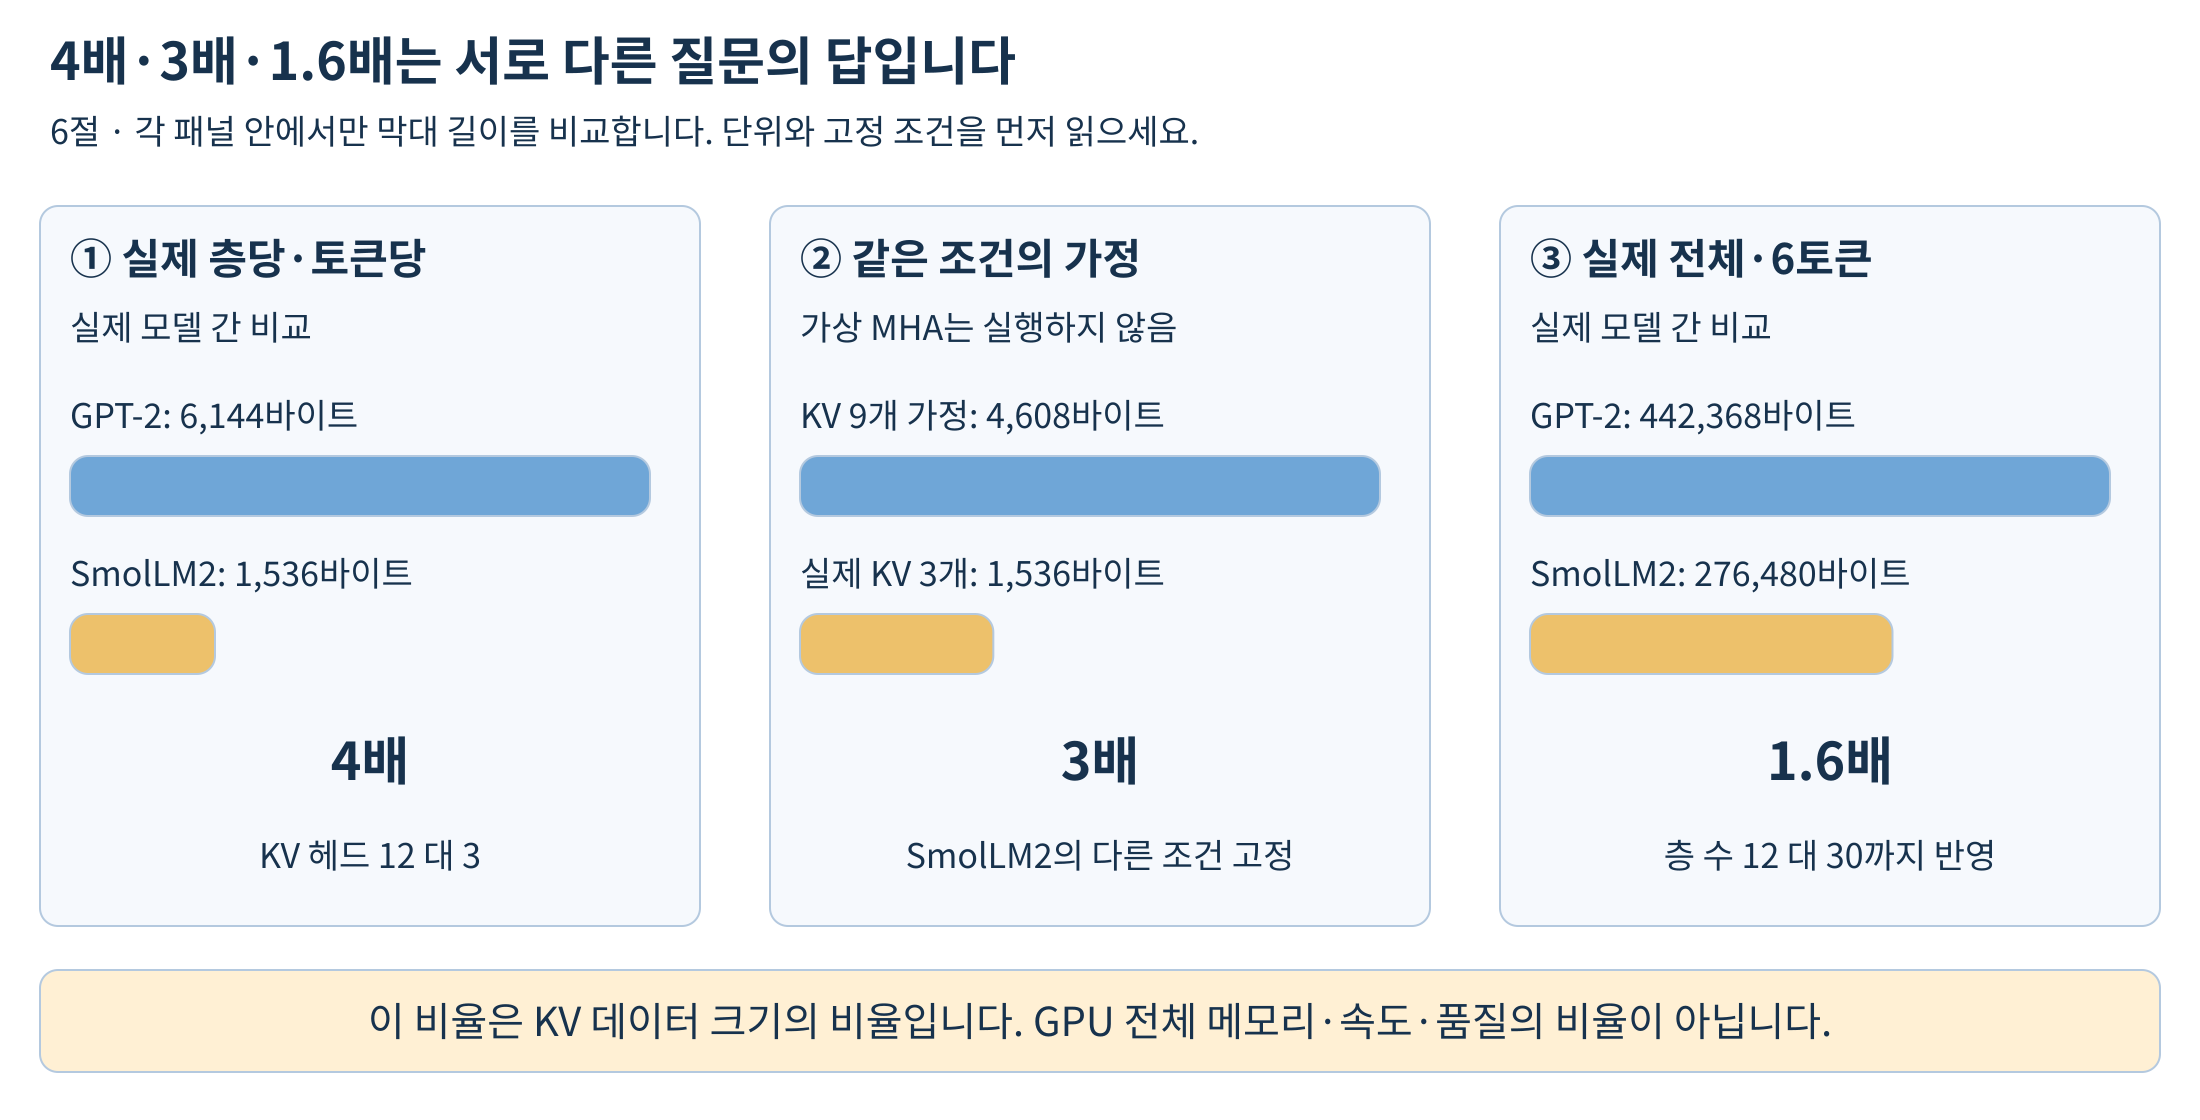

**그림 설명:** 각 패널의 막대 길이는 그 패널 안에서만 비교합니다. 가운데는 **KV 공유 효과를 분리한 가정**, 양옆은 **실제 두 모델의 저장량 비교**입니다.


### 코드 설명: 세 가지 비율을 구분하여 결론 내리기
저장된 실제 6토큰 KV 데이터는 GPT-2 442368바이트, SmolLM2 276480바이트입니다. 층당·토큰당 비율은 4배지만 전체 캐시 비율은 1.6배입니다. 전체 합에는 GPT-2의 12개 층과 SmolLM2의 30개 층이 각각 반영되기 때문입니다. 비교 단위를 말하지 않고 ‘GQA가 4배 절약된다’고 일반화하면 서로 다른 구조의 차이가 섞입니다.

별도로 SmolLM2의 다른 조건을 그대로 두고 KV 헤드만 9개라고 가정한 계산은 3배입니다. 이것은 실제로 변형 모델을 실행한 결과가 아니라 통제된 조건의 이론적 저장량 비교입니다. 각 출력이 실제 측정인지 가정 계산인지 표시해 설명하세요. 어느 비율도 그대로 추론 속도 향상, 전체 메모리 절감률, 또는 품질 차이를 의미하지 않습니다.


In [6]:
gpt = metrics["GPT-2"]
smol = metrics["SmolLM2"]
assert gpt["tokens"] == smol["tokens"] == 6
assert gpt["total_bytes"] == 442368
assert smol["total_bytes"] == 276480
# 실제 두 모델의 층당·토큰당 비율입니다. 서로 다른 KV 헤드 수가 포함됩니다.
cross_model_per_layer_ratio = gpt["per_layer_per_token"] / smol["per_layer_per_token"]
# 총량에는 층 수 차이도 반영됩니다. 층당 비율과 구분합니다.
whole_model_ratio = gpt["total_bytes"] / smol["total_bytes"]
# 가상 정규화 계산만 수행합니다. 모델 구성이나 실제 캐시는 바꾸지 않습니다.
# 다른 조건을 고정하고 KV 헤드만 Q와 같다고 가정한 계산이며 모델을 변경하지 않습니다.
smol_hypothetical_mha_per_layer = 2 * SPECS["SmolLM2"]["q_heads"] * 64 * 4
# 같은 SmolLM2 조건의 가상 MHA와 실제 GQA를 나눕니다. 두 실제 모델 간 비율과 구분합니다.
fixed_geometry_ratio = smol_hypothetical_mha_per_layer / smol["per_layer_per_token"]
assert cross_model_per_layer_ratio == 4.0
assert fixed_geometry_ratio == 3.0
assert whole_model_ratio == 1.6
print("Actual GPT-2 / SmolLM2 six-token payload:", gpt["total_bytes"], smol["total_bytes"])
print("Actual cross-model per-layer ratio:", cross_model_per_layer_ratio)
print("Hypothetical fixed-Smol-geometry ratio (not a tested model):", fixed_geometry_ratio)
print("Actual whole-model payload ratio:", whole_model_ratio)
print("[PASS] 실제 캐시와 조건을 고정한 이론 계산 구분")
print("[PASS] Lesson 05 완료")

Actual GPT-2 / SmolLM2 six-token payload: 442368 276480
Actual cross-model per-layer ratio: 4.0
Hypothetical fixed-Smol-geometry ratio (not a tested model): 3.0
Actual whole-model payload ratio: 1.6
[PASS] 실제 캐시와 조건을 고정한 이론 계산 구분
[PASS] Lesson 05 완료


### 출력 설명: 실행 기록과 확인 범위

- 실제 모델의 **층당·토큰당** 비율 4는 6,144를 1,536으로 나눈 값입니다. 이 비교에는 KV 헤드가 12개 대 3개라는 모델 간 차이가 포함되어 있으므로 GQA만의 순수 효과라고 부르지 않습니다.
- 가정 계산의 비율 3은 SmolLM2의 다른 조건을 고정하고 KV 헤드만 3개에서 Q와 같은 9개로 늘렸을 때의 비교입니다. 코드로 새 MHA 모델을 만들거나 실행한 결과가 아닙니다.
- 실제 **전체 모델·6토큰** 비율 1.6은 442,368을 276,480으로 나눈 값입니다. 층 수가 12 대 30으로 다르기 때문에 층당 비율 4와 달라집니다. 따라서 이 기록의 SmolLM2 K/V payload는 GPT-2의 62.5%입니다.
- PASS는 실제 측정값과 조건을 고정한 가정 계산을 구분하고 세 비율을 확인합니다. 추론이 1.6배 빠르다거나 GPU 전체 메모리를 같은 비율로 절약한다는 결론은 이 출력만으로 낼 수 없습니다.


## 정리와 자기 점검
Q 헤드 수와 KV 헤드 수를 구분하고, 실제 캐시 shape을 읽어 보세요. 캐시를 가진 상태에서 한 토큰을 처리하면 시퀀스 길이 축이 증가합니다. 다시 검증하려면 커널을 재시작하고 처음부터 실행합니다.


- [ ] 새 토큰 ID를 선택한 순간과 모델이 그 ID를 처리한 순간 중 언제 캐시 길이가 증가하나요?

   **핵심 답과 이유:** 모델이 새 ID를 처리하여 그 위치의 K/V를 만든 순간입니다. 선택만 했을 때는 기존 캐시가 그대로이며, 이번 실습에서는 새 토큰 하나의 forward 뒤 시퀀스 축이 6에서 7로 늘었습니다.

- [ ] KV 헤드 수 비율만으로 두 모델 전체 캐시 크기 비율을 정할 수 없는 이유는 무엇인가요?

   **핵심 답과 이유:** 전체 크기에는 KV 헤드뿐 아니라 층 수·토큰 수·헤드당 차원·자료형의 바이트 수·문장 수가 함께 곱해지기 때문입니다. 이번 두 모델은 층당 비율이 4이지만 층 수가 12 대 30이어서 전체 6토큰 payload 비율은 1.6입니다.


### 참고: KV 캐시와 FlashAttention은 무엇을 줄이나요?

> **KV 캐시는 다음 단계에서 다시 할 일을 줄이고, FlashAttention은 지금 해야 할 어텐션 계산을 더 효율적으로 실행합니다.**
>
> - **KV 캐시(KV cache)**는 **토큰 생성 단계 사이의 재계산**을 줄입니다. 첫 토큰을 만든 뒤 다음 토큰을 만드는 과정에서, 앞서 처리한 토큰의 Key·Value를 다시 만들지 않고 저장된 값을 읽어 씁니다. 새 Query가 과거 Key·Value를 참조하는 어텐션 계산 자체는 여전히 필요합니다.
> - **FlashAttention 1·2**는 **한 번의 어텐션 계산 안에서 GPU 메모리 읽기·쓰기**를 줄입니다. [FlashAttention](https://arxiv.org/abs/2205.14135)은 큰 점수 행렬을 통째로 메모리에 저장하지 않고 작은 타일로 나누어 계산합니다. [FlashAttention-2](https://arxiv.org/abs/2307.08691)는 이 방법을 유지하면서 같은 헤드 안의 일도 여러 GPU 작업 그룹에 더 효율적으로 나눕니다.

같은 입력과 마스크를 기준으로 FlashAttention은 **어텐션 수식이나 볼 수 있는 위치를 바꾸지 않습니다.** 캐시에서 과거 K·V를 가져온 뒤 그 값으로 FlashAttention을 계산할 수 있으므로 둘은 함께 쓸 수 있습니다. 이번 실습에서는 KV 캐시의 모양과 크기, 점수 일치를 확인했으며 FlashAttention의 실행 여부나 속도는 비교하지 않습니다.

**코드 옵션과 연결하기:** FlashAttention도 같은 Scaled Dot-Product Attention을 계산합니다. `attn_implementation="sdpa"`는 PyTorch에 실행 커널 선택을 맡기고, `"flash_attention_2"`는 지원되는 환경에서 FlashAttention-2 구현을 명시적으로 요청합니다. 이 실습은 기존 `"eager"` 구현에서 KV 캐시를 관찰합니다.


## 참고 자료

- Ainslie 외, [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://aclanthology.org/2023.emnlp-main.298/), §2와 Figure 1: MHA·GQA·MQA 구조 비교. 해당 논문의 성능 결과를 이번 두 모델의 실측으로 간주하지 않습니다.
- Shazeer, [Fast Transformer Decoding: One Write-Head is All You Need](https://arxiv.org/abs/1911.02150): MQA와 K·V 공유의 원 논문. 여기서는 MQA 모델을 실행하지 않았습니다.
- [Transformers v5.23.0 cache 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/cache_utils.py): DynamicCache의 layers와 실제 keys/values 텐서 확인.
- [GPT-2 config](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json), [GPT-2 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt2/modeling_gpt2.py).
- [SmolLM2 config](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json), [Llama 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/llama/modeling_llama.py).
- 고정 가중치: GPT-2 revision `607a30d783dfa663caf39e06633721c8d4cfcd7e`, SHA256 `248dfc3911869ec493c76e65bf2fcf7f615828b0254c12b473182f0f81d3a707`; SmolLM2 revision `93efa2f097d58c2a74874c7e644dbc9b0cee75a2`, SHA256 `80521b40281d6ce74e35c9282c22539e75aa0ac8578892b2a59955ef78d55da1`.